---
title: "3.2.d Escenarios: sequías más frecuentes y más calientes"
short_title: "d. Escenarios"
subtitle: "Proyecciones CMIP6 de días secos consecutivos, SPEI y temperatura; tendencia de las vaciantes"
description: "Escenarios de cambio climático para la sequía en Leticia con el ensamble CMIP6 del Banco Mundial."
keywords: [sequía, CMIP6, SPEI, días secos consecutivos, escenarios, Amazonía]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/32_sequia/d_escenarios.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

El Panel Científico por la Amazonía advierte que las sequías fuertes pasaron de unas cuatro por siglo a cuatro
en menos de 25 años, y que la sinergia entre sequía, deforestación, fuego y degradación puede llevar al bosque a
un punto de no retorno [@marengo2024spa; @flores2024]. Esta página reúne lo que proyecta el ensamble CMIP6 para
la celda de Leticia y lo que implicaría extrapolar la tendencia observada de las vaciantes.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from leticia import fuentes, hidro, viz

## 1. Proyecciones del ensamble CMIP6 (CCKP, Banco Mundial)

In [3]:
VARS = {"cdd": "máx. días secos consecutivos", "spei12": "SPEI-12 (adimensional)", "pr": "lluvia anual (mm)",
        "tasmax": "temperatura máxima media (°C)"}
tabla = fuentes.cckp_tabla(list(VARS))
base = fuentes.cckp_historico(list(VARS))
piv = tabla.pivot_table(index=["variable", "escenario"], columns=["periodo", "percentil"], values="valor")
piv.index = piv.index.set_levels([[VARS[v] for v in piv.index.levels[0]], [viz.NOMBRE_ESC[e] for e in piv.index.levels[1]]])
display(Markdown("**Cambio respecto a 1995–2014** (mediana y rango p10–p90 del ensamble):"))
display(piv.round(2))
display(base.rename(index=VARS).round(2).to_frame("climatología 1995–2014"))

**Cambio respecto a 1995–2014** (mediana y rango p10–p90 del ensamble):

periodo                                 2040-2059                2080-2099               
percentil                                  median     p10    p90    median     p10    p90
variable                      escenario                                                  
máx. días secos consecutivos  SSP1-2.6       0.75   -0.45   1.45      0.60   -0.40   1.55
                              SSP2-4.5       0.70   -0.40   2.25      1.05   -0.30   3.45
                              SSP5-8.5       0.80   -0.40   3.20      2.15    0.20   7.90
lluvia anual (mm)             SSP1-2.6     -70.34 -179.48 140.45    -40.82 -238.36 137.22
                              SSP2-4.5     -70.01 -253.13  87.79   -103.10 -417.60 205.68
                              SSP5-8.5    -105.25 -370.10 213.22   -259.05 -641.10 285.86
SPEI-12 (adimensional)        SSP1-2.6      -0.43   -1.12   0.52     -0.50   -1.24   0.44
                              SSP2-4.5      -0.62   -1.20   0.26     -0.90   -1.79   0.75
                              SSP5-8.5      -0.93   -1.84   0.90     -2.00   -2.70   1.11
temperatura máxima media (°C) SSP1-2.6       1.04    0.57   1.95      1.09    0.37   2.31
                              SSP2-4.5       1.24    0.78   2.33      2.18    0.89   3.77
                              SSP5-8.5       1.78    0.72   3.18      4.83    2.05   9.06

,climatología 1995–2014
máx. días secos consecutivos,4.20
SPEI-12 (adimensional),-0.15
lluvia anual (mm),"2,906.55"
temperatura máxima media (°C),29.86


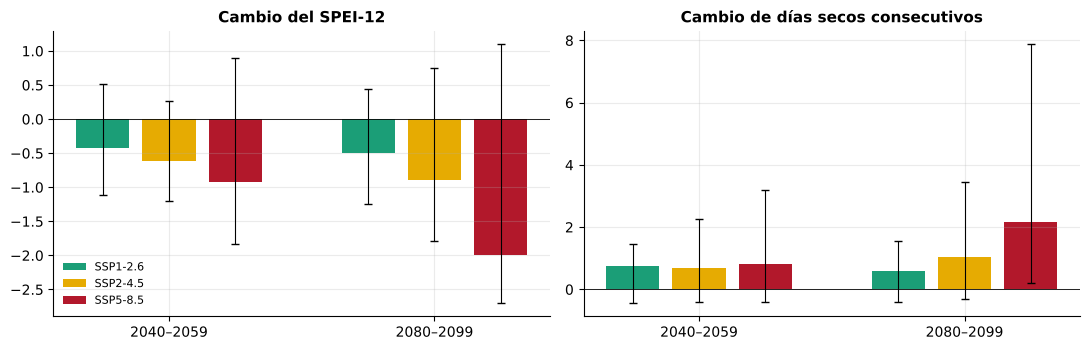

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, var, titulo in ((ax[0], "spei12", "Cambio del SPEI-12"), (ax[1], "cdd", "Cambio de días secos consecutivos")):
    sub = tabla[tabla.variable == var]
    for k, per in enumerate(("2040-2059", "2080-2099")):
        for j, esc in enumerate(("ssp126", "ssp245", "ssp585")):
            v = sub[(sub.escenario == esc) & (sub.periodo == per)].set_index("percentil")["valor"]
            x = k * 4 + j
            a.bar(x, v["median"], color=viz.ESCENARIOS[esc], label=viz.NOMBRE_ESC[esc] if k == 0 else None)
            a.errorbar(x, v["median"], yerr=[[v["median"] - v["p10"]], [v["p90"] - v["median"]]], color="k", capsize=3, lw=0.8)
    a.set_xticks([1, 5])
    a.set_xticklabels(["2040–2059", "2080–2099"])
    a.axhline(0, color="k", lw=0.6)
    a.set_title(titulo)
ax[0].legend(fontsize=8)
fig.tight_layout()

In [5]:
viz.pie(viz.nota_fuente("proyecciones_cckp"))

*Fuente: Banco Mundial – Climate Change Knowledge Portal (CCKP) — CMIP6 0,25° (reducción de escala estadística), SSP1-2.6, SSP2-4.5, SSP5-8.5.*

**Lectura.** Aunque la lluvia anual cambia poco en la mediana, el **SPEI**, que incluye la evaporación, se
desplaza hacia condiciones más secas en todos los escenarios, y más con mayores emisiones: el calor es el motor
principal de la sequía futura, como lo fue en 2023 [@clarke2024wwa]. Los modelos subestiman además el efecto de
la deforestación sobre el reciclaje de humedad, que reduce la lluvia en la estación seca [@marengo2021spa22].

## 2. Si la tendencia observada de las vaciantes continúa

In [6]:
nivel = hidro.limpiar_nivel(fuentes.nivel_rio())
minimos = hidro.extremos_anuales(nivel, "min")["valor"]
mk = hidro.mann_kendall(minimos)
from scipy import stats
params = hidro.ajustar_gev(minimos.values, minimos=True)
filas = []
for anio in (2026, 2040, 2050):
    desplazamiento = mk["sen"] * (anio - 2026)
    p = stats.genextreme.sf(-(400 - desplazamiento), *params)
    filas.append({"año": anio, "desplazamiento del mínimo típico (m)": desplazamiento / 100,
                  "probabilidad anual de bajar de 4 m (%)": 100 * p})
display(pd.DataFrame(filas).set_index("año").round(2))
display(Markdown(f"Pendiente de Sen de los mínimos anuales: **{mk['sen']:.1f} cm/año** (p = {mk['p']:.2f}). La extrapolación supone que "
                 "la tendencia de las últimas décadas continúa sin cambios; es un escenario de sensibilidad, no una proyección hidrológica."))

,desplazamiento del mínimo típico (m),probabilidad anual de bajar de 4 m (%)
año,,
2026,-0.00,8.84
2040,-0.56,14.47
2050,-0.95,19.27


Pendiente de Sen de los mínimos anuales: **-4.0 cm/año** (p = 0.41). La extrapolación supone que la tendencia de las últimas décadas continúa sin cambios; es un escenario de sensibilidad, no una proyección hidrológica.

:::{note} Dos fuerzas que se suman
El riesgo de aislamiento de Leticia en aguas bajas resulta de **dos procesos independientes**: el clima, que
hace las vaciantes más profundas y frecuentes, y la dinámica del cauce, que aleja el brazo navegable de la
ciudad ([3.3](../33_erosion/index.md)). Perú y Colombia acordaron en 2025 completar estudios técnicos sobre la
sedimentación del sector Atacuari–Leticia y un plan de monitoreo del río [@forbes2025navegabilidad].
:::